**Human Movement Intelligence | Presented by: Reza Saadatyar (2026)**

**03 | Full Development Audit and Classical Grouped Cross-Validation**

![HARTH full Development workflow](../../images/03_consolidated_workflow.svg)

**Objective:** Audit the complete 29-participant HARTH Development cohort, examine eight-class activity coverage and GroupKFold feasibility, and compare Dummy, Logistic Regression and Random Forest over five participant-disjoint folds. Report paired held-out-participant differences between Random Forest and Logistic Regression.

**Dataset:** Official pinned NTNU AI Lab HARTH v2.0 recordings with six lower-back/thigh acceleration channels at a nominal 50 Hz. Timestamp-safe, label-pure 100-sample windows use a 50-sample stride and five deterministic statistics per channel (30 features). The supervised task is the eight documented source classes (1–8).

**Notebook scope:** Reuse the **ten-person Stage 02 feature CSV** from `output/`, acquire and process only the **19 remaining Development participants** once, and create one aligned 29-person feature table. The audit and classical evaluation then consume these same rows without rebuilding the full cohort.

**Evaluation boundary:** S023 and S032 remain excluded from every Development model fit and score. These subjects were already inspected in earlier exploratory work; later same-study assessment must not be called strictly blind or external. Within each grouped fold, all fitted preprocessing and models use Train participants only.

**Reading order:** saved Stage 02 features → remaining-source inventory and preparation → full Development cohort → source exclusions and activity support → five-fold classical CV → paired participant-level interpretation → research outputs.


**00. Colab Repository Setup**

In [1]:
# ======================== 00. Colab Repository Setup =========================

# -------------------------- 1. Repository Checkout ---------------------------
from pathlib import Path
import subprocess

repo_url = "https://github.com/RezaSaadatyar/human-movement-intelligence.git"
repo_path = Path("/content") / repo_url.rsplit("/", 1)[-1].removesuffix(".git")

if not repo_path.exists():
    subprocess.run(["git", "clone", "-q", repo_url, str(repo_path)], check=True)

# ---------------------------- 2. Open Repository -----------------------------
%cd {repo_path}

/content/human-movement-intelligence


**01. Imports and Research Environment**


In [2]:
# =================== 01. Imports and Research Environment ====================

# ------------------ 1. Repository and Notebook Environment -------------------
from python_modules.core.colab_setup import setup_colab
root = setup_colab("wearable_activity_recognition")

# ------------------------ 2. Numerical Data Analysis -------------------------
import numpy as np
import pandas as pd

# ----------------- 3. Scientific Plots and Notebook Display ------------------
import matplotlib.pyplot as plt
from IPython.display import display
from core.plot_style import plot_style, save_figure
plot_style(font_family="DejaVu Sans", title_size=12.5,
           title_weight="normal", label_size=11.5, label_weight="normal",
           tick_size=11, legend_size=10, figure_dpi=100,
           figure_size=(9, 4))

# ------------- 4. HARTH Source and Grouped Evaluation Utilities --------------
from harth_data import (
    HARTH_SUBJECTS, ACTIVITY_NAMES, SENSOR_COLUMNS,
    prepare_harth_feature_cohort,
)
from core.data_splitting import audit_group_class_coverage
from core.group_cross_validation import (
    evaluate_group_cross_validation, compare_models_by_subject,
)
from core.output_download import download_outputs_from_colab

# ----------------- 5. Dataset and Stage Output Configuration -----------------
output_dir = root / "wearable_activity_recognition/output"
data_dir = root / "data/raw/harth_v2"
output_dir.mkdir(parents=True, exist_ok=True)
RESERVED_TEST = {"S023", "S032"}
DEVELOPMENT_SUBJECTS = sorted(set(HARTH_SUBJECTS) - RESERVED_TEST)
TEN_SUBJECTS = {
    "S024", "S025", "S027", "S028", "S034",
    "S035", "S029", "S030", "S031", "S033",
}
REMAINING_SUBJECTS = sorted(set(DEVELOPMENT_SUBJECTS) - TEN_SUBJECTS)
TASK_CLASSES = tuple(range(1, 9))
FEATURE_METHODS = ("mean", "std", "rms", "peak_to_peak", "waveform_length")
FEATURE_COLUMNS = [
    f"{c}__{m}" for c in SENSOR_COLUMNS for m in FEATURE_METHODS
]
WINDOW_COLUMNS = [
    "subject_id", "start_index", "end_index_exclusive",
    "label", "label_purity",
]
print("Development participants:", len(DEVELOPMENT_SUBJECTS))
print("Previously processed:", len(TEN_SUBJECTS))
print("Remaining original CSVs:", len(REMAINING_SUBJECTS))

Repository up to date.
Development participants: 29
Previously processed: 10
Remaining original CSVs: 19


**02. Read Saved Ten-Person Development Features**

Read the Stage 02 CSV rather than processing the same ten participant recordings again. Preserve source-index metadata, feature column order and previously audited excluded activity codes.

In [3]:
# ============== 02. Read Current Stage 02 Development Features ===============

# ----------- 1. Load Previously Saved Source Windows and Features ------------
ten_saved = pd.read_csv(
    output_dir / "02_development10_statistical_features.csv"
)
ten_source = pd.read_csv(output_dir / "02_ten_dev_cohort_summary.csv")
ten_excluded = pd.read_csv(
    output_dir / "02_ten_dev_excluded_source_codes.csv"
)
window_fields = ["window_" + col for col in WINDOW_COLUMNS]
missing = set(window_fields + FEATURE_COLUMNS) - set(ten_saved.columns)
if missing:
    raise ValueError(f"Stage 02 columns unavailable: {sorted(missing)}")
ten_metadata = ten_saved[window_fields].copy()
ten_metadata.columns = WINDOW_COLUMNS
ten_features = ten_saved[FEATURE_COLUMNS].copy()

# ------------ 2. Maintain Source Identity and Aligned Task Labels ------------
if set(ten_metadata["subject_id"]) != TEN_SUBJECTS:
    raise ValueError("Stage 02 has unexpected participant IDs.")
if set(ten_metadata["subject_id"]) & RESERVED_TEST:
    raise ValueError("Reserved Test participants occur in Development.")
if not ten_metadata["label"].isin(TASK_CLASSES).all():
    raise ValueError("Non-task activity labels are present.")
if not np.isfinite(ten_features.to_numpy()).all():
    raise ValueError("Stage 02 features contain nonfinite values.")
display(ten_metadata.head())
print("Reused Stage 02 feature matrix:", ten_features.shape)

,subject_id,start_index,end_index_exclusive,label,label_purity
0,S024,0,100,6,1.0
1,S024,50,150,6,1.0
2,S024,200,300,6,1.0
3,S024,350,450,6,1.0
4,S024,400,500,6,1.0


Reused Stage 02 feature matrix: (31903, 30)


**03. Inspect and Process the Remaining Nineteen Participants**

Report local source availability, then load the remaining 19 original recordings only. The shared feature function performs the same time-continuous, label-pure windowing and five statistical transformations once per person, excluding out-of-task labels after windowing.

**Source coverage:** The 19 additional Development participants contribute 100,494 eligible eight-class windows. Source S037 included 1,422 rows with undocumented activity code 10; the code is reported without an invented activity meaning. The source inventory identifies which official recordings are already cached and which must be obtained for feature construction.


In [4]:
# ============== 03. Prepare Remaining Original Source Features ===============

# ------------------ 1. Inspect the Current Source Inventory ------------------
inventory = pd.DataFrame([
    {"subject_id": subject,
     "source": ("Stage 02 saved features" if subject in TEN_SUBJECTS
                else "Official HARTH v2.0 CSV"),
     "original_csv_available": (data_dir / f"{subject}.csv").is_file()}
    for subject in DEVELOPMENT_SUBJECTS
])
display(inventory)
print("Remaining source files absent locally:", int((~inventory.loc[
    inventory["subject_id"].isin(REMAINING_SUBJECTS),
    "original_csv_available"
]).sum()))

# --------------- 2. Build Only the Newly Required Feature Sets ---------------
new_features, new_metadata, new_overview, new_excluded = (
    prepare_harth_feature_cohort(
        subjects=REMAINING_SUBJECTS, data_dir=data_dir,
        task_classes=TASK_CLASSES,
        window_size=100, step_size=50, sampling_rate=50,
    )
)
display(new_overview)
display(new_excluded)
print("New Development feature matrix:", new_features.shape)

,subject_id,source,original_csv_available
0,S006,Official HARTH v2.0 CSV,False
1,S008,Official HARTH v2.0 CSV,False
2,S009,Official HARTH v2.0 CSV,False
3,S010,Official HARTH v2.0 CSV,False
4,S012,Official HARTH v2.0 CSV,False
5,S013,Official HARTH v2.0 CSV,False
6,S014,Official HARTH v2.0 CSV,False
7,S015,Official HARTH v2.0 CSV,False
8,S016,Official HARTH v2.0 CSV,False
9,S017,Official HARTH v2.0 CSV,False


Remaining source files absent locally: 19
Downloaded 59,108,125 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S006.csv
HARTH subject S006: 408,709 rows, 6 sensors
Input signal: 408,709 samples, 6 channels
Candidate windows: 8,173
Retained windows: 7,441 | Shape: (7441, 6, 100)
Rejected candidates: 732
Input windows: (7441, 6, 100)
Feature matrix: (7441, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length
Downloaded 60,603,857 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S008.csv
HARTH subject S008: 418,989 rows, 6 sensors
Input signal: 418,989 samples, 6 channels
Candidate windows: 8,378
Retained windows: 7,564 | Shape: (7564, 6, 100)
Rejected candidates: 814
Input windows: (7564, 6, 100)
Feature matrix: (7564, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length
Downloaded 22,408,603 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S009.csv
HARTH subject S009: 154,464 rows, 6 sensors
Input signal: 154,464 samples, 6 

/content/human-movement-intelligence/wearable_activity_recognition/code/src/harth_data.py:203: UserWarning: Unexpected HARTH activity codes: [10] (1,422 rows in S037.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(


HARTH subject S037: 206,379 rows, 6 sensors
Input signal: 206,379 samples, 6 channels
Candidate windows: 4,126
Retained windows: 3,468 | Shape: (3468, 6, 100)
Rejected candidates: 658
Input windows: (3468, 6, 100)
Feature matrix: (3468, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length
Downloaded 15,185,213 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S038.csv
HARTH subject S038: 184,992 rows, 6 sensors
Input signal: 184,992 samples, 6 channels
Candidate windows: 3,698
Retained windows: 3,355 | Shape: (3355, 6, 100)
Rejected candidates: 343
Input windows: (3355, 6, 100)
Feature matrix: (3355, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length
Eligible dataset: 19 subjects, 100,494 windows, 30 features


,subject_id,raw_samples,retained_windows,eligible_windows,excluded_windows,undocumented_raw_rows,task_classes_present
0,S006,408709,7441,6708,733,0,7
1,S008,418989,7564,7392,172,0,6
2,S009,154464,2885,201,2684,0,4
3,S010,351649,6077,6077,0,0,6
4,S012,382414,7309,7309,0,0,8
5,S013,369077,6451,6402,49,0,8
6,S014,366487,6409,6299,110,0,8
7,S015,418392,7626,7453,173,0,8
8,S016,355418,6484,6272,212,0,8
9,S017,366609,6841,6678,163,0,8


,subject_id,source_code,source_activity,excluded_windows
0,S006,13,Cycling seated,474
1,S006,14,Cycling standing,55
2,S006,130,Cycling seated inactive,204
3,S008,13,Cycling seated,147
4,S008,14,Cycling standing,11
5,S008,130,Cycling seated inactive,2
6,S008,140,Cycling standing inactive,12
7,S009,13,Cycling seated,2328
8,S009,14,Cycling standing,190
9,S009,130,Cycling seated inactive,165


New Development feature matrix: (100494, 30)


**04. Create One Reusable Full Development Cohort**

Assemble the ten saved and nineteen newly processed feature groups in ascending source-participant order. Preserve alignment between 30 numerical features and the five original window metadata fields. Save the current 29-person Development table once.

In [5]:
# ============= 04. Combine Twenty-Nine Participant Feature Sets ==============

# -------------- 1. Concatenate Features in Stable Subject Order --------------
feature_parts, metadata_parts = [], []
for subject in DEVELOPMENT_SUBJECTS:
    if subject in TEN_SUBJECTS:
        chosen_features, chosen_meta = ten_features, ten_metadata
    else:
        chosen_features, chosen_meta = new_features, new_metadata
    selected = chosen_meta["subject_id"].eq(subject)
    feature_parts.append(
        chosen_features.loc[selected].reset_index(drop=True)
    )
    metadata_parts.append(
        chosen_meta.loc[selected].reset_index(drop=True)
    )
features = pd.concat(feature_parts, ignore_index=True)
metadata = pd.concat(metadata_parts, ignore_index=True)

# -------------- 2. Check Essential Group and Feature Alignment ---------------
if len(features) != len(metadata):
    raise ValueError("Feature rows and labels are misaligned.")
if set(metadata["subject_id"]) != set(DEVELOPMENT_SUBJECTS):
    raise ValueError("Expected Development participants are missing.")
if set(metadata["subject_id"]) & RESERVED_TEST:
    raise ValueError("Reserved Test participants entered Development.")
if not np.isfinite(features.to_numpy()).all():
    raise ValueError("Development features contain nonfinite values.")

# -------------- 3. Save Current Full Development Feature Table ---------------
current_features = pd.concat([
    metadata.add_prefix("window_"), features
], axis=1)
full_file = output_dir / "03_development29_statistical_features.csv"
current_features.to_csv(full_file, index=False)
print("Full Development feature matrix:", features.shape)
print("Saved reusable table:", full_file)

Full Development feature matrix: (132397, 30)
Saved reusable table: /content/human-movement-intelligence/wearable_activity_recognition/output/03_development29_statistical_features.csv


**05. Summarise Source Coverage and Excluded Activity Codes**

Reuse the ten-person audit from Stage 02 and combine it with source information for the remaining 19 participants. Distinguish raw samples, valid signal windows and documented eight-class eligible windows; keep cycling and undocumented source-code exclusions visible.

**Development cohort:** The combined table contains **132,397 eligible windows from 29 Development participants**, represented by 30 statistical features per window. The source audit also records out-of-task retained windows and undocumented codes 10, 11 and 17 without assigning new activity labels. Excluded-source windows are not training examples in this eight-class task.


In [6]:
# ============ 05. Combine Source Coverage and Exclusion Summaries ============

# ---------- 1. Reconstruct the Existing Ten-Person Audit from CSVs -----------
ten_n = ten_metadata.groupby("subject_id").size()
ten_k = ten_metadata.groupby("subject_id")["label"].nunique()
ten_overview = ten_source[[
    "subject_id", "raw_samples", "retained_windows",
    "unmapped_raw_rows",
]].rename(columns={"unmapped_raw_rows": "undocumented_raw_rows"}).copy()
ten_overview["eligible_windows"] = (
    ten_overview["subject_id"].map(ten_n).astype(int)
)
ten_overview["excluded_windows"] = (
    ten_overview["retained_windows"] - ten_overview["eligible_windows"]
)
ten_overview["task_classes_present"] = (
    ten_overview["subject_id"].map(ten_k).astype(int)
)

# --------------- 2. Combine Source and Excluded-Label Records ----------------
overview = pd.concat([ten_overview, new_overview], ignore_index=True)
overview = overview.set_index("subject_id").loc[
    DEVELOPMENT_SUBJECTS
].reset_index()
excluded = pd.concat([ten_excluded, new_excluded], ignore_index=True)
excluded = excluded[[
    "subject_id", "source_code", "source_activity", "excluded_windows",
]].sort_values(["subject_id", "source_code"]).reset_index(drop=True)
display(overview)
display(excluded)
print("Total eight-class windows:", len(metadata))
print("Out-of-task retained source windows:",
      int(excluded["excluded_windows"].sum()))

,subject_id,raw_samples,retained_windows,undocumented_raw_rows,eligible_windows,excluded_windows,task_classes_present
0,S006,408709,7441,0,6708,733,7
1,S008,418989,7564,0,7392,172,6
2,S009,154464,2885,0,201,2684,4
3,S010,351649,6077,0,6077,0,6
4,S012,382414,7309,0,7309,0,8
5,S013,369077,6451,0,6402,49,8
6,S014,366487,6409,0,6299,110,8
7,S015,418392,7626,0,7453,173,8
8,S016,355418,6484,0,6272,212,8
9,S017,366609,6841,0,6678,163,8


,subject_id,source_code,source_activity,excluded_windows
0,S006,13,Cycling seated,474
1,S006,14,Cycling standing,55
2,S006,130,Cycling seated inactive,204
3,S008,13,Cycling seated,147
4,S008,14,Cycling standing,11
5,S008,130,Cycling seated inactive,2
6,S008,140,Cycling standing inactive,12
7,S009,13,Cycling seated,2328
8,S009,14,Cycling standing,190
9,S009,130,Cycling seated inactive,165


Total eight-class windows: 132397
Out-of-task retained source windows: 11708


**06. Audit the Five Participant-Disjoint Fold Splits**

Use the existing GroupKFold audit once on the complete cohort, preserving the per-participant activity matrix and fold-level class availability. Feasibility is not itself evidence of classification performance.

**Fold class coverage:** Each of the five participant-disjoint folds contains all eight declared activities in both Train and Validation, with no missing training or validation classes. This does not imply comparable class proportions or activity support across participants.


In [7]:
# =============== 06. Audit Grouped Development Class Coverage ================

# ------------- 1. Audit Fold Membership and Participant Classes --------------
coverage, fold_audit = audit_group_class_coverage(
    labels=metadata["label"].to_numpy(),
    group_ids=metadata["subject_id"].to_numpy(),
    classes=TASK_CLASSES,
    n_splits=5,
)
coverage.columns = [f"{code}: {ACTIVITY_NAMES[code]}" for code in TASK_CLASSES]

# ------------------ 2. Inspect Fold and Class Availability -------------------
display(coverage)

display(fold_audit)
print("Missing training classes by fold:",
      fold_audit[["fold", "missing_train_classes"]].to_dict("records"))

print("Missing validation classes by fold:",
      fold_audit[["fold", "missing_validation_classes"]].to_dict("records"))

Group audit: 29 subjects, 132,397 windows, 8 declared classes, 5 folds
Folds missing training classes: 0


,1: Walking,2: Running,3: Shuffling,4: Stairs ascending,5: Stairs descending,6: Standing,7: Sitting,8: Lying
S006,315,0,59,19,26,998,5036,255
S008,294,0,259,10,11,977,5841,0
S009,91,0,0,7,9,94,0,0
S010,3263,0,229,93,47,1519,926,0
S012,170,39,47,64,32,370,6215,372
S013,501,65,378,42,26,809,4449,132
S014,342,41,92,70,42,827,4715,170
S015,900,50,36,99,72,1161,3886,1249
S016,663,48,113,5,30,850,3784,779
S017,602,92,54,141,80,510,4339,860


,fold,train_subjects,validation_subjects,train_windows,validation_windows,training_classes_present,validation_classes_present,missing_train_classes,missing_validation_classes
0,1,"S006, S008, S009, S012, S013, S014, S016, S017...","S010, S015, S022, S026, S037, S038",106134,26263,8,8,(),()
1,2,"S006, S009, S010, S012, S013, S014, S015, S017...","S008, S016, S025, S028, S033, S036",105037,27360,8,8,(),()
2,3,"S006, S008, S010, S013, S015, S016, S017, S018...","S009, S012, S014, S019, S027, S030",106915,25482,8,8,(),()
3,4,"S008, S009, S010, S012, S014, S015, S016, S017...","S006, S013, S018, S029, S031, S034",104400,27997,8,8,(),()
4,5,"S006, S008, S009, S010, S012, S013, S014, S015...","S017, S020, S021, S024, S035",107102,25295,8,8,(),()


Missing training classes by fold: [{'fold': 1, 'missing_train_classes': ()}, {'fold': 2, 'missing_train_classes': ()}, {'fold': 3, 'missing_train_classes': ()}, {'fold': 4, 'missing_train_classes': ()}, {'fold': 5, 'missing_train_classes': ()}]
Missing validation classes by fold: [{'fold': 1, 'missing_validation_classes': ()}, {'fold': 2, 'missing_validation_classes': ()}, {'fold': 3, 'missing_validation_classes': ()}, {'fold': 4, 'missing_validation_classes': ()}, {'fold': 5, 'missing_validation_classes': ()}]


**07. Visualise Participant Activity and Class Support**

Produce the two-panel coverage plot from the original data audit: eligible windows by activity and participant, and the number of independent participants supporting each activity.

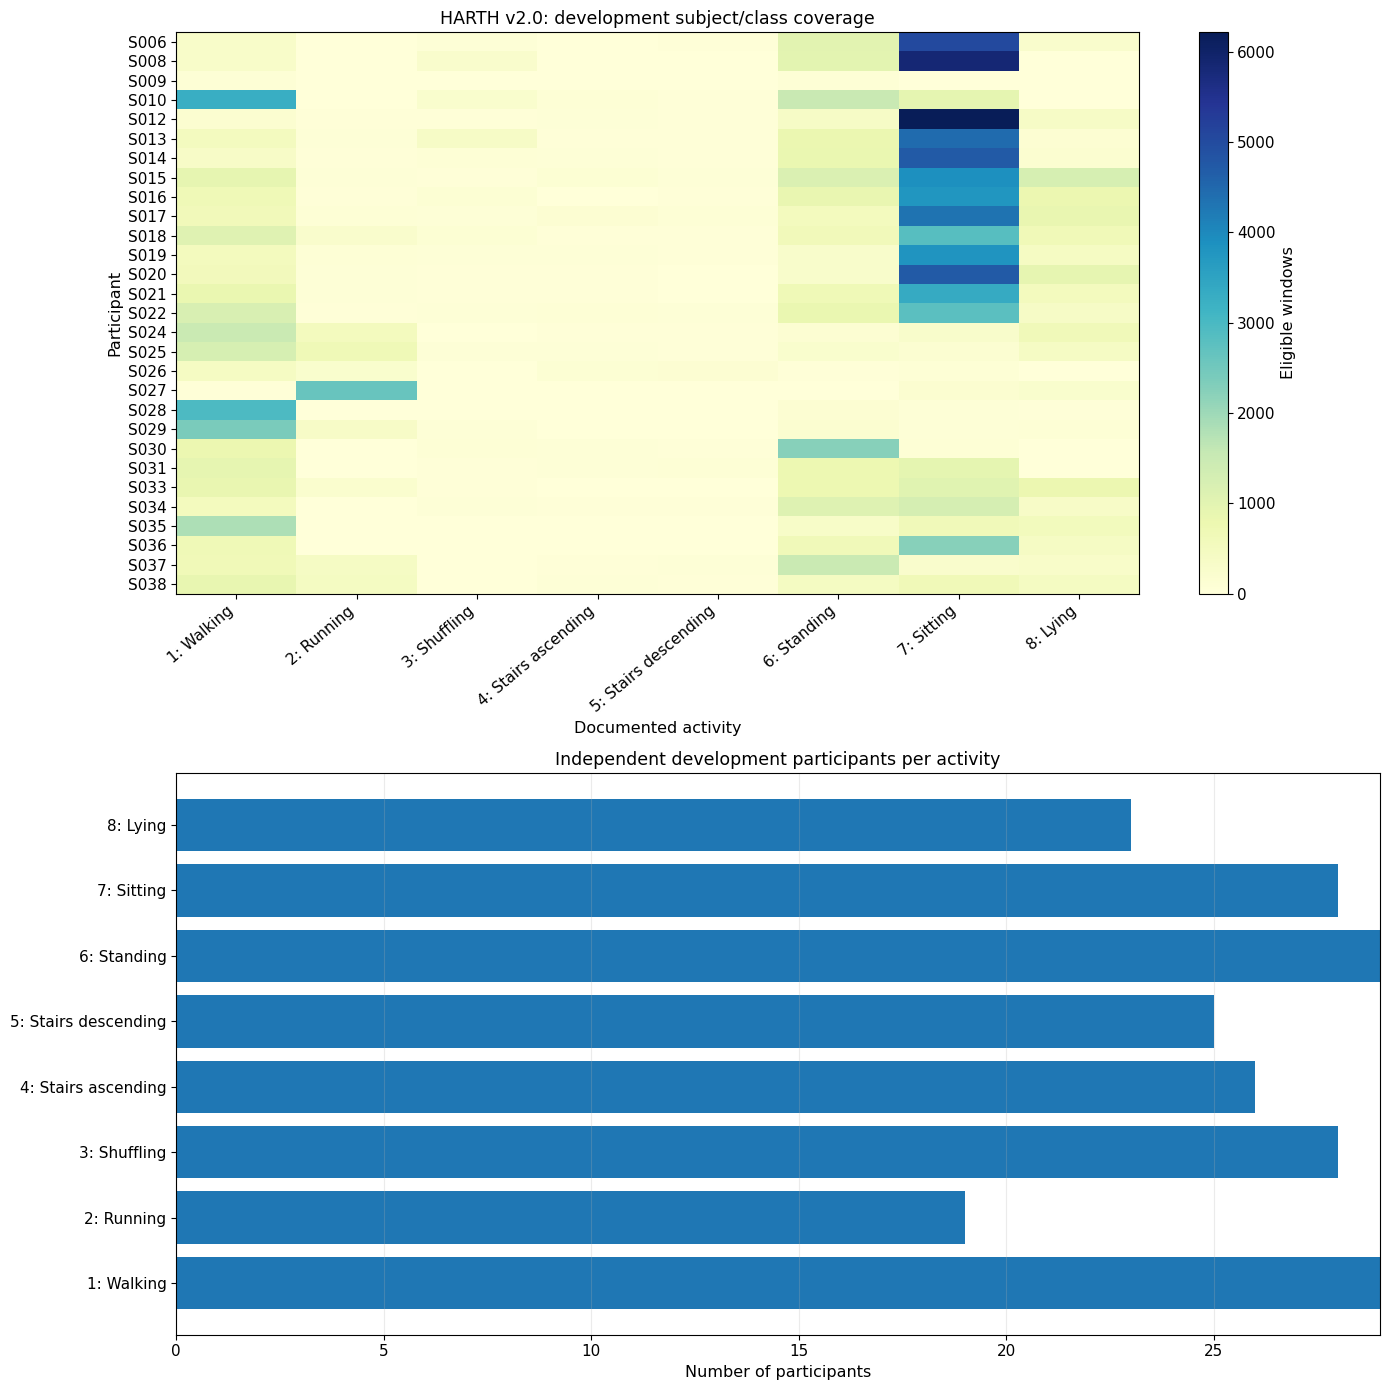

In [8]:
# ============= 07. Plot Independent Participant Activity Support =============

# ---------------- 1. Display Source Activity Counts by Person ----------------
fig, axes = plt.subplots(2, 1, figsize=(14, 14))
matrix = coverage.to_numpy()
heat = axes[0].imshow(matrix, aspect="auto", cmap="YlGnBu")
axes[0].set_xticks(np.arange(coverage.shape[1]), coverage.columns,
                   rotation=40, ha="right")
axes[0].set_yticks(np.arange(coverage.shape[0]), coverage.index)
axes[0].set(title="HARTH v2.0: development subject/class coverage",
            xlabel="Documented activity", ylabel="Participant")
fig.colorbar(heat, ax=axes[0], label="Eligible windows")

subject_support = (coverage > 0).sum(axis=0)

axes[1].barh(subject_support.index, subject_support.to_numpy())
axes[1].set(title="Independent development participants per activity",
            xlabel="Number of participants", xlim=(0, len(DEVELOPMENT_SUBJECTS)))
axes[1].grid(axis="x", alpha=0.25)
fig.tight_layout()
save_figure(fig, output_dir / "03_development_class_coverage.png")
plt.show()

**08. Train Three Classical Models in Five Development Folds**

Fit the original Dummy, Logistic Regression and Random Forest baselines on five participant-disjoint folds. Each fold's Logistic Regression scaler and model are fitted exclusively on its Train windows.

**Five-fold Development comparison:** On the full 29-person Development cohort, five-fold mean Macro F1 was **0.8353 ± 0.0423** for Random Forest, **0.7721 ± 0.0568** for Logistic Regression and **0.0815 ± 0.0118** for the most-frequent Dummy baseline (mean ± fold SD). These are fold-wise validation scores using the fixed eight-class task, not an independent Test result. The folds share the Development population and their SD does not quantify uncertainty across independent study replications.


In [9]:
# =========== 08. Evaluate Three Development Models with GroupKFold ===========

# -------------- 1. Fit New Models within Each Development Fold ---------------
fold_results, subject_results, summary = evaluate_group_cross_validation(
    features=features.to_numpy(),
    labels=metadata["label"].to_numpy(),
    group_ids=metadata["subject_id"].to_numpy(),
    classes=TASK_CLASSES,
    n_splits=5, random_state=42,
)
display(summary.round(4))

# -------------------- 2. Display Fold-Level Model Metrics --------------------
display(fold_results[[
    "fold", "model", "validation_subjects",
    "validation_windows", "validation_classes_present",
    "macro_f1", "balanced_accuracy",
]].round(4))

Fold 1: Train=23 subjects, Validation=6 subjects
Dummy (most frequent): Validation Macro F1 = 0.0616
Logistic Regression: Validation Macro F1 = 0.8501
Random Forest: Validation Macro F1 = 0.8313
Fold 2: Train=23 subjects, Validation=6 subjects
Dummy (most frequent): Validation Macro F1 = 0.0810
Logistic Regression: Validation Macro F1 = 0.7919
Random Forest: Validation Macro F1 = 0.8680
Fold 3: Train=23 subjects, Validation=6 subjects
Dummy (most frequent): Validation Macro F1 = 0.0927
Logistic Regression: Validation Macro F1 = 0.7548
Random Forest: Validation Macro F1 = 0.8857
Fold 4: Train=23 subjects, Validation=6 subjects
Dummy (most frequent): Validation Macro F1 = 0.0857
Logistic Regression: Validation Macro F1 = 0.6938
Random Forest: Validation Macro F1 = 0.8094
Fold 5: Train=24 subjects, Validation=5 subjects
Dummy (most frequent): Validation Macro F1 = 0.0862
Logistic Regression: Validation Macro F1 = 0.7699
Random Forest: Validation Macro F1 = 0.7818


,model,fold_macro_f1_mean,fold_macro_f1_sd,fold_macro_f1_min,fold_macro_f1_max,subject_macro_f1_fixed_mean,subject_macro_f1_observed_mean
0,Random Forest,0.8353,0.0423,0.7818,0.8857,0.7310,0.8182
1,Logistic Regression,0.7721,0.0568,0.6938,0.8501,0.6952,0.7726
2,Dummy (most frequent),0.0815,0.0118,0.0616,0.0927,0.0616,0.0677


,fold,model,validation_subjects,validation_windows,validation_classes_present,macro_f1,balanced_accuracy
0,1,Logistic Regression,"S010, S015, S022, S026, S037, S038",26263,8,0.8501,0.9164
1,1,Random Forest,"S010, S015, S022, S026, S037, S038",26263,8,0.8313,0.8189
2,1,Dummy (most frequent),"S010, S015, S022, S026, S037, S038",26263,8,0.0616,0.1250
3,2,Random Forest,"S008, S016, S025, S028, S033, S036",27360,8,0.8680,0.8825
4,2,Logistic Regression,"S008, S016, S025, S028, S033, S036",27360,8,0.7919,0.9047
5,2,Dummy (most frequent),"S008, S016, S025, S028, S033, S036",27360,8,0.0810,0.1250
6,3,Random Forest,"S009, S012, S014, S019, S027, S030",25482,8,0.8857,0.8640
7,3,Logistic Regression,"S009, S012, S014, S019, S027, S030",25482,8,0.7548,0.9015
8,3,Dummy (most frequent),"S009, S012, S014, S019, S027, S030",25482,8,0.0927,0.1250
9,4,Random Forest,"S006, S013, S018, S029, S031, S034",27997,8,0.8094,0.8380


**09. Compare Held-Out Fold Macro F1**

Plot all five Development folds for the three classical models. Means and individual fold values should be considered together; these are not independent external replications.

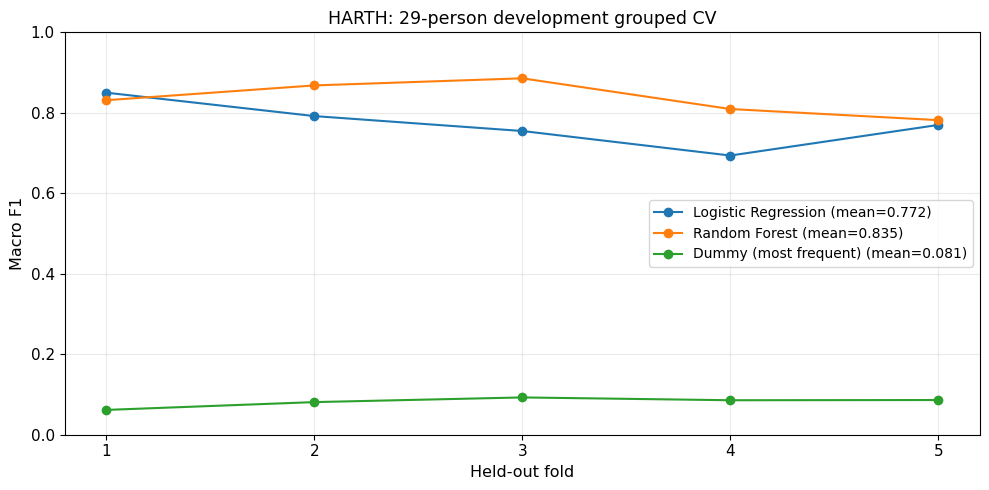

In [10]:
# ============ 09. Visualise Five-Fold Classical Model Performance ============

# -------------- 1. Plot Validation Fold Macro F1 by Classifier ---------------
fig, ax = plt.subplots(figsize=(10, 5))

for model_name, table in fold_results.groupby("model", sort=False):
    table = table.sort_values("fold")
    ax.plot(table["fold"], table["macro_f1"], marker="o",
            label=f"{model_name} (mean={table['macro_f1'].mean():.3f})")

ax.set(title="HARTH: 29-person development grouped CV",
       xlabel="Held-out fold", ylabel="Macro F1",
       ylim=(0, 1), xticks=[1, 2, 3, 4, 5])
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
save_figure(fig, output_dir / "03_development_cv_fold_macro_f1.png")
plt.show()

**10. Compare Random Forest and Logistic Regression by Participant**

Use paired fixed eight-class Macro F1 for the exact same held-out Development participants. Positive signed differences favour Random Forest; the comparison is descriptive and not a statistical significance test.

**Paired participant comparison:** Random Forest obtained a higher fixed eight-class Macro F1 for **19 of 29** held-out Development participants, compared with **10 of 29** for Logistic Regression (no ties). The participant-equal mean signed difference (Random Forest minus Logistic Regression) was **+0.0358**; the median was **+0.0244**. These are descriptive paired results; no inferential significance or external generalisation claim follows from them.


,subject_id,score_a,score_b,difference_a_minus_b
0,S006,0.7265,0.6126,0.1139
1,S008,0.5334,0.5089,0.0244
2,S009,0.4302,0.3345,0.0957
3,S010,0.4505,0.5154,-0.0649
4,S012,0.9066,0.8823,0.0243
5,S013,0.8506,0.9102,-0.0596
6,S014,0.8614,0.6979,0.1634
7,S015,0.7815,0.8053,-0.0238
8,S016,0.9251,0.8807,0.0444
9,S017,0.7281,0.7639,-0.0358


,model_a,model_b,metric,participants,mean_difference,median_difference,model_a_wins,model_b_wins,ties
0,Random Forest,Logistic Regression,macro_f1_fixed_task,29,0.035807,0.024443,19,10,0


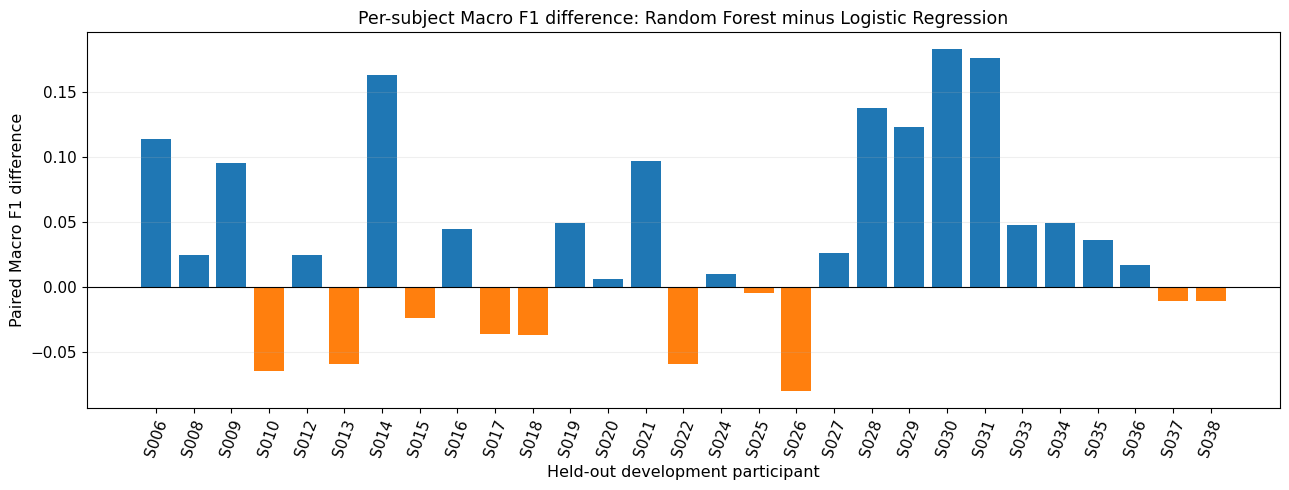

In [11]:
# ============= 10. Compare Models on Identical Held-Out Subjects =============

# ------------------ 1. Match Participant-Level Model Scores ------------------
paired, paired_summary = compare_models_by_subject(
    subject_results,
    model_a="Random Forest",
    model_b="Logistic Regression",
    score_column="macro_f1_fixed_task",  # Use the same eight-class metric for both models.
)
display(paired.round(4))
display(pd.DataFrame([paired_summary]))

# --------------- 2. Visualise Signed Paired Score Differences ----------------
fig, ax = plt.subplots(figsize=(13, 5))

bar_colours = ["tab:blue" if value >= 0 else "tab:orange"
               for value in paired["difference_a_minus_b"]]
ax.bar(paired["subject_id"], paired["difference_a_minus_b"], color=bar_colours)
ax.axhline(0, color="black", linewidth=0.8)
ax.set(title="Per-subject Macro F1 difference: Random Forest minus Logistic Regression",
       xlabel="Held-out development participant", ylabel="Paired Macro F1 difference")
ax.tick_params(axis="x", rotation=70)
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
save_figure(fig, output_dir / "03_random_forest_logistic_regression_difference.png")
plt.show()

**11. Relate Model Performance to Participant Activity Support**

Merge eligible window counts, number of observed classes and fixed-task per-person model Macro F1. This comparison makes the limitations of small or unbalanced activity support visible.

**Interpretation of unequal activity support:** Not every participant contributes all eight classes. For example, **S009 has 201 eligible windows covering four classes**. Per-person Macro F1 calculated over the fixed eight-class task is therefore different from a score restricted to classes observed for that person. The participant-equal means are **0.7310** for Random Forest and **0.6952** for Logistic Regression; these are not interchangeable with their fold-mean scores.


In [12]:
# =========== 11. Compare Individual Activity Support and Model F1 ============

# -------------- 1. Join Source Activity Counts and Model Scores --------------
person_support = pd.DataFrame({
    "subject_id": coverage.index,
    "eligible_windows": coverage.sum(axis=1).to_numpy(),
    "observed_classes": (coverage > 0).sum(axis=1).to_numpy(),
})
comparison = subject_results.pivot(
    index="subject_id", columns="model", values="macro_f1_fixed_task"
).reset_index()
participant_table = person_support.merge(comparison, on="subject_id", how="left")
display(participant_table.round(4))

print("Independent development subjects represented:", len(participant_table))

,subject_id,eligible_windows,observed_classes,Dummy (most frequent),Logistic Regression,Random Forest
0,S006,6708,7,0.1072,0.6126,0.7265
1,S008,7392,6,0.1103,0.5089,0.5334
2,S009,201,4,0.0000,0.3345,0.4302
3,S010,6077,6,0.0331,0.5154,0.4505
4,S012,7309,8,0.1149,0.8823,0.9066
5,S013,6402,8,0.1025,0.9102,0.8506
6,S014,6299,8,0.1070,0.6979,0.8614
7,S015,7453,8,0.0857,0.8053,0.7815
8,S016,6272,8,0.0941,0.8807,0.9251
9,S017,6678,8,0.0985,0.7639,0.7281


Independent development subjects represented: 29


**12. Save Research Evidence and Package Current Outputs**

Write source, class-coverage and evaluation results using the stable `03_` filename prefix. The full feature table is already saved in Section 04. Package the corresponding research files for optional manual retrieval from Colab.

In [13]:
# ================== 12. Export Development Research Results ===================

# --------------- 1. Save Source and Fold Class-Coverage Tables ---------------
inventory.to_csv(output_dir / "03_development_source_inventory.csv",
                 index=False)
overview.to_csv(output_dir / "03_development_cohort_summary.csv",
                index=False)
excluded.to_csv(output_dir / "03_excluded_source_codes.csv",
                index=False)
coverage.rename_axis("subject_id").reset_index().to_csv(
    output_dir / "03_development_subject_class_coverage.csv", index=False
)
fold_audit.to_csv(output_dir / "03_development_fold_class_audit.csv",
                  index=False)
subject_support.rename_axis("activity").reset_index(
    name="supporting_subjects"
).to_csv(
    output_dir / "03_development_activity_subject_support.csv",
    index=False,
)

# ----------- 2. Save Cross-Validation and Paired Comparison Tables -----------
summary.to_csv(output_dir / "03_development_cv_model_summary.csv",
               index=False)
fold_results.to_csv(output_dir / "03_development_cv_fold_metrics.csv",
                    index=False)
subject_results.to_csv(
    output_dir / "03_development_cv_participant_metrics.csv", index=False
)
paired.to_csv(
    output_dir / "03_paired_model_participant_comparison.csv", index=False
)
pd.DataFrame([paired_summary]).to_csv(
    output_dir / "03_paired_model_summary.csv", index=False
)
participant_table.to_csv(
    output_dir / "03_development_participant_comparison.csv", index=False
)

# --------------- 3. Display Results and Package Research Files --------------
display(summary.round(4))
display(pd.DataFrame([paired_summary]).round(4))
print("Development subjects:", metadata["subject_id"].nunique())
print("Eight-class windows:", len(metadata))
download_outputs_from_colab(
    folder="wearable_activity_recognition/output", stage="03"
)

,model,fold_macro_f1_mean,fold_macro_f1_sd,fold_macro_f1_min,fold_macro_f1_max,subject_macro_f1_fixed_mean,subject_macro_f1_observed_mean
0,Random Forest,0.8353,0.0423,0.7818,0.8857,0.7310,0.8182
1,Logistic Regression,0.7721,0.0568,0.6938,0.8501,0.6952,0.7726
2,Dummy (most frequent),0.0815,0.0118,0.0616,0.0927,0.0616,0.0677


,model_a,model_b,metric,participants,mean_difference,median_difference,model_a_wins,model_b_wins,ties
0,Random Forest,Logistic Regression,macro_f1_fixed_task,29,0.0358,0.0244,19,10,0


Development subjects: 29
Eight-class windows: 132397
------------------------------------------------------------------------
Notebook stage: 03
Files packaged: 16
  + 03_development29_statistical_features.csv
  + 03_development_activity_subject_support.csv
  + 03_development_class_coverage.png
  + 03_development_cohort_summary.csv
  + 03_development_cv_fold_macro_f1.png
  + 03_development_cv_fold_metrics.csv
  + 03_development_cv_model_summary.csv
  + 03_development_cv_participant_metrics.csv
  + 03_development_fold_class_audit.csv
  + 03_development_participant_comparison.csv
  + 03_development_source_inventory.csv
  + 03_development_subject_class_coverage.csv
  + 03_excluded_source_codes.csv
  + 03_paired_model_participant_comparison.csv
  + 03_paired_model_summary.csv
  + 03_random_forest_logistic_regression_difference.png
Download ZIP from Colab Contents: /content/wearable_activity_recognition_Stage_03_Outputs.zip


**13. Scientific Interpretation and Next Research Boundary**

The full Development feature cohort contains **132,397 eligible eight-class windows from 29 participants**. Each window has 30 deterministic statistical predictors and aligned source metadata. The ten-person feature table is reused from the preceding analysis, and 19 additional participants are processed using the same timestamp-aware segmentation and feature definitions.

**Source quality and class support:** Only documented HARTH activity codes 1–8 enter the supervised comparisons. Cycling and other out-of-task windows are excluded, while undocumented source codes 10, 11 and 17 are retained in the audit without invented activity meanings. All five participant-disjoint folds contain the eight classes in both Train and Validation, but individual coverage is uneven: S009, for example, contributes 201 eligible windows spanning four activities.

**Five-fold Development results:** Mean fold Macro F1 (fold SD) is **0.8353 (0.0423)** for Random Forest, **0.7721 (0.0568)** for Logistic Regression and **0.0815 (0.0118)** for the most-frequent Dummy baseline. The corresponding participant-equal fixed eight-class Macro F1 averages are **0.7310** and **0.6952** for Random Forest and Logistic Regression. Fold-level and participant-level averages have distinct aggregation units; the folds are not independent study replications.

**Paired participant comparison:** Random Forest scores higher for 19 of the 29 matched held-out Development participants; Logistic Regression scores higher for ten. The participant-equal signed difference averages **+0.0358** (median **+0.0244**) in favour of Random Forest. These comparisons are descriptive; they do not establish significance, universal participant-level improvement or performance in a new source population.

**Evaluation boundary:** S023 and S032 are excluded from Development fitting and scoring. Both were previously inspected descriptively, so subsequent qualified same-collection assessment is not strictly blind or external validation. The older bounded three-fold deep-learning benchmark uses different sample limits and experimental conditions and is not directly interchangeable with these classical five-fold metrics.

**Outputs and dependencies:** The `03_` CSV outputs include the aligned 29-person feature table, source and fold coverage, cross-validation metrics and matched participant comparisons; PNG files display class coverage and score variation. Downstream statistical-feature analyses consume `03_development29_statistical_features.csv`. Temporal CNN experiments require original time-series windows instead of the 30-column statistical-feature representation.
